# Лабораторна 5. Власне донавчання: класифікація відгуків громадян про держпослуги

**Коротко:** донавчаю `Qwen3-1.7B` методом SFT з LoRA, щоб модель визначала **намір** відгуку громадянина
(подяка, скарга, питання / прохання про допомогу, пропозиція, нейтральне) на датасеті **UAReviews**.
Порівнюю з тією самою моделлю з найкращим промптом і з найпростішим базовим рівнем.

Запуск: Google Colab, GPU T4 → *Runtime → Run all*. Тривалість на T4 ≈ 65 хв (з них тренування 48 хв).

## 1.1. Задача

У лабораторній 3 я зробив "Диспетчер звернень громади", де zero-shot модель сортувала звернення за відділами.
Але перед тим, як шукати відділ, треба зрозуміти, **що саме людина хоче**: подякувати, поскаржитись, отримати допомогу
чи запропонувати ідею. У Дії, ЦНАПах і міських радах щодня збирають тисячі відгуків, і реагувати на них треба по-різному:

| намір | що робить організація |
|---|---|
| **питання / прохання про допомогу** | відповісти людині якнайшвидше, передати в підтримку |
| **скарга** | розібратися з проблемою, відповісти, порахувати статистику по установах |
| **пропозиція** | передати продуктовій команді / керівництву |
| **подяка** | показати працівникам, врахувати в рейтингу |
| **нейтральне** | архів, без дії |

- **Користувач:** оператор підтримки чи аналітик Мінцифри / міськради.
- **Вхід:** текст відгуку українською (від кількох слів до кількох абзаців, із суржиком, помилками, емодзі).
- **Вихід:** одна мітка з п'яти - за нею відгук потрапляє в потрібну чергу.

**Чому не промпт і не RAG.**
- Межі класів - це **правила розмітки конкретного датасету**, а не загальновідомі поняття. "Працівники молодці, але черга 2 години, не вистачає рук" - це скарга чи пропозиція? Опис "пропозиція = ідея щодо покращення" модель трактує по-своєму, а анотатори - по-своєму. Пояснити ці конвенції промптом складно, а 5 000 прикладів передають їх точно.
- Головна цінність - **рідкісні класи** (питання 5 %, пропозиції 3 %): промпт мала модель легко "зливає" в скаргу чи подяку.
- **Вартість:** промпт з описами класів і прикладами в кілька разів довший за сам відгук, а платити за нього доведеться на кожному з тисяч відгуків щодня. Донавчена модель працює з коротким промптом.
- **RAG тут не допомагає:** відповідь не залежить від зовнішніх знань, яких немає в моделі, - потрібно навчити саме *поведінку* (класифікацію за заданою схемою).
- Велика LLM через API впоралась би краще за малу з промптом, але відгуки містять персональні дані громадян; маленьку донавчену модель можна запустити локально (див. лабу 4).

## 1.2. Модель і дані

**Модель: `Qwen/Qwen3-1.7B`** (гібридна instruct-модель, той самий ряд, що в демо 02-03).
- **Instruct, а не base:** нам потрібно, щоб модель відповідала одним словом у форматі розмови, а для оцінки "до донавчання" потрібна модель, яка вміє виконувати інструкції. З base порівняння з промптом було б нечесним.
- **1.7B:** у демо 03 на схожій задачі Qwen3-0.6B без донавчання давала точність category лише 37.9 % проти 62.7 % у 1.7B, а українською 0.6B ще слабша, тож порівняння "до" було б заниженим. 1.7B у fp16 займає ≈ 3.4 ГБ, тож LoRA з батчем 16 вміщається в T4 (15 ГБ) без квантизації. 4B уже потребувала б QLoRA і тренувалась би в ≈ 2.5 раза довше.
- Режим міркування вимкнено (`enable_thinking=False`): для класифікації він лише множить кількість токенів.

**Дані: [KSE-RESEARCH-Group/UAReviews](https://huggingface.co/datasets/KSE-RESEARCH-Group/UAReviews)** (Kyiv School of Economics, UNLP 2026).
- **Ліцензія:** CC-BY-4.0.
- **Обсяг:** 11 580 відгуків; відгуки про послуги Дії, ЦНАПи, міськради, надані Мінцифри, + невелика частина з корпусу COSMUS.
- **Формат:** JSONL, поля `content` (текст), `rating`, `final_category` (5 намірів), `final_emotion` (7 емоцій), `split` (`train` / `test` / `challenge`). Використовую `content` → `final_category`.

In [56]:
!pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "datasets" "accelerate" scikit-learn
!pip uninstall -q -y torchao

In [57]:
import json, random, re, time, gc, collections
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from datasets import load_dataset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
pd.set_option("display.max_colwidth", 160)
print(torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "немає")

2.14.1+cu130 | GPU: Tesla T4


In [58]:
raw = load_dataset("KSE-RESEARCH-Group/UAReviews", data_files="benchmark_v1_splits.jsonl", split="train")
df = raw.to_pandas()

LABELS = {
    "Gratitude / Positive Feedback": "подяка",
    "Complaint / Dissatisfaction":   "скарга",
    "Question / Request for Help":   "питання",
    "Suggestion / Idea":             "пропозиція",
    "Neutral Comment":               "нейтральне",
}
CLASSES = list(LABELS.values())
df["label"] = df["final_category"].map(LABELS)
df["content"] = df["content"].str.strip()
df = df[df["content"].str.len() > 0].drop_duplicates("content")

print("Усього:", len(df))
pd.crosstab(df["label"], df["split"], margins=True)

Усього: 11565


split,challenge,test,train,All
label,,,,
нейтральне,70,58,289,417
питання,86,97,432,615
подяка,1116,1109,5206,7431
пропозиція,63,56,257,376
скарга,400,410,1916,2726
All,1735,1730,8100,11565


**Кілька прикладів** (по два на клас):

In [59]:
df[df.split == "train"].groupby("label").sample(2, random_state=1)[["label", "rating", "content"]]

,label,rating,content
3304,нейтральне,5.0,Податкова інспекція на території колишнього дитсадка.
7402,нейтральне,5.0,"Площа з багатою історією, статую охороняли, щоб вона не постраждала від війни"
2900,питання,NaN,"Та ось би телефончиків більше, тоді й додзвонитися реальніше 🙄\nШвидше буде приїхати 😄\nЗ питань землі може хто знає, кому потрібно звернутися?…"
7387,питання,NaN,"Нічого не відбулось, коментарі як були, так і залишились, вас ніхто не блокував в даному чаті. Уточніть що ви маєте на увазі під ""тіло чата"""
6956,подяка,5.0,"Адміністратор Шевчук- Малькут, все оперативно і швидко"
4938,подяка,5.0,"Дуже задоволена послугами цієї компанії. Все було виконано оперативно, на високому професійному рівні та вчасно. Дякую."
265,пропозиція,NaN,"Академія КРОК допоможе вам визначити вам вашу професію, і потім ви зрозумієте, що йти це не ваше."
3593,пропозиція,NaN,"Так в Дії повинно бути написано, або мати посилання на закон Закон 2923-IX https://zakon.rada.gov.ua"
2231,скарга,1.0,"Свою обл. раду вони переробили на висоті, будівля дуже гарна, але я ось не розумію чому щодня мер спостерігаючи з вікна не помічає, що фонтан не працює вже ..."
3124,скарга,4.0,"Вид шикарний! Підйом – тихий жах. Чи не кількість сходів лякає, а жахливий стан. Потік людей не контролюється, сходи вузькі, у деяких місцях справді страшно."


### Поділ

- **Тест** - офіційний спліт `test` авторів датасету (≈ 1 730 відгуків). Він ніде не бере участі ні в тренуванні, ні у виборі промпту чи гіперпараметрів.
- **Валідація** - 10 % від `train`, стратифіковано за класом: на ній дивимось validation loss під час тренування і обираємо найкращий промпт для моделі "до".
- **Тренування** - решта `train`. Подяк у даних 64 %, тому я **обмежую їх 2 500 прикладами** (решту класів беру повністю): інакше модель бачила б переважно подяки й гірше вчила рідкісні класи, а тренування було б удвічі довшим. Спліт `challenge` не використовую.
- Додатково перевіряю, що жоден текст тесту не потрапив у тренування.

In [60]:
test_df = df[df.split == "test"].reset_index(drop=True)
pool    = df[df.split == "train"]
train_df, val_df = train_test_split(pool, test_size=0.10, stratify=pool["label"], random_state=SEED)

MAX_GRATITUDE = 2500
train_df = pd.concat([
    train_df[train_df.label == "подяка"].sample(MAX_GRATITUDE, random_state=SEED),
    train_df[train_df.label != "подяка"],
]).sample(frac=1, random_state=SEED).reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

assert not set(test_df.content) & set(train_df.content), "тест протік у тренування!"
assert not set(val_df.content) & set(train_df.content)

pd.DataFrame({
    "train": train_df.label.value_counts(), "val": val_df.label.value_counts(), "test": test_df.label.value_counts(),
}).loc[CLASSES].assign(**{"test, %": lambda t: (t["test"] / t["test"].sum() * 100).round(1)})

,train,val,test,"test, %"
label,,,,
подяка,2500,520,1109,64.1
скарга,1724,192,410,23.7
питання,389,43,97,5.6
пропозиція,231,26,56,3.2
нейтральне,260,29,58,3.4


## 1.3. Модель до донавчання

**Метрика - macro-F1** (середнє F1 по 5 класах). Accuracy тут оманлива: модель, яка на все відповідає "подяка",
має accuracy ≈ 64 %, але для задачі вона марна - пропускає всі питання й пропозиції, а саме вони найцінніші.
Macro-F1 дає кожному класу однакову вагу. Додатково дивлюсь accuracy, F1 по класах і **частку валідних відповідей**
(модель відповіла рівно однією з п'яти міток).

**Базовий рівень:** "завжди найчастіший клас" (подяка).

In [61]:
def report(y_true, y_pred, name):
    return {
        "модель": name,
        "macro-F1": round(f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0), 3),
        "accuracy": round(accuracy_score(y_true, y_pred), 3),
        "валідних, %": round(100 * np.mean([p in CLASSES for p in y_pred]), 1),
        **{f"F1 {c}": round(f, 3) for c, f in zip(CLASSES, f1_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0))},
    }

results = [report(test_df.label, ["подяка"] * len(test_df), "завжди 'подяка'")]
pd.DataFrame(results)

,модель,macro-F1,accuracy,"валідних, %",F1 подяка,F1 скарга,F1 питання,F1 пропозиція,F1 нейтральне
0,завжди 'подяка',0.156,0.641,100.0,0.781,0.0,0.0,0.0,0.0


In [62]:
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen3-1.7B"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16, device_map="cuda:0")
model.generation_config.pad_token_id = tok.pad_token_id
print(f"Параметрів: {model.num_parameters()/1e9:.2f} B | GPU пам'ять: {torch.cuda.memory_allocated()/2**30:.2f} ГБ")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Параметрів: 1.72 B | GPU пам'ять: 6.62 ГБ


### Промпти

Пробую два промпти й обираю кращий **на валідації** (не на тесті):
- **короткий** - лише перелік міток; саме з ним потім тренуватиму модель;
- **детальний** - визначення кожного класу, правила для спірних випадків і по одному прикладу на клас (few-shot з тренувального набору).

In [63]:
MAX_CHARS = 1000

SHORT_SYSTEM = (
    "Класифікуй відгук громадянина про державну чи муніципальну послугу. "
    "Відповідай одним словом: подяка, скарга, питання, пропозиція або нейтральне."
)

DETAILED_SYSTEM = '''Ти класифікуєш відгуки громадян про державні й муніципальні послуги (Дія, ЦНАП, міськради, установи).
Визнач головний намір автора і відповідай РІВНО одним словом з переліку:
- подяка - автор задоволений, хвалить, дякує, рекомендує установу чи працівника;
- скарга - автор незадоволений: черги, грубість, помилки, не працює послуга, не може додзвонитися;
- питання - автор питає щось або просить допомогти розв'язати його ситуацію;
- пропозиція - автор пропонує, що змінити чи покращити, або дає пораду іншим;
- нейтральне - опис, новина, довідкова інформація чи посилання без оцінки й прохання.
Правила: якщо є і похвала, і проблема - обирай те, що переважає. Прохання про допомогу - це питання, навіть якщо автор незадоволений.
Не пояснюй, не додавай розділових знаків.'''

def few_shot_examples(n_per_class=1, seed=0):
    shots = []
    for c in CLASSES:
        cand = train_df[(train_df.label == c) & train_df.content.str.len().between(40, 220)]
        for _, r in cand.sample(n_per_class, random_state=seed).iterrows():
            shots += [{"role": "user", "content": r.content}, {"role": "assistant", "content": c}]
    return shots

SHOTS = few_shot_examples()

def build_messages(text, style):
    text = text[:MAX_CHARS]
    if style == "short":
        return [{"role": "system", "content": SHORT_SYSTEM}, {"role": "user", "content": text}]
    return [{"role": "system", "content": DETAILED_SYSTEM}, *SHOTS, {"role": "user", "content": text}]

def render(text, style):
    return tok.apply_chat_template(build_messages(text, style), tokenize=False,
                                   add_generation_prompt=True, enable_thinking=False)

ex = test_df.content[0]
for s in ["short", "detailed"]:
    print(f"{s:9s}: {len(tok(render(ex, s)).input_ids):4d} токенів промпту")
print("\n--- короткий промпт, як його бачить модель ---\n" + render(ex, "short"))

short    :  115 токенів промпту
detailed :  772 токенів промпту

--- короткий промпт, як його бачить модель ---
<|im_start|>system
Класифікуй відгук громадянина про державну чи муніципальну послугу. Відповідай одним словом: подяка, скарга, питання, пропозиція або нейтральне.<|im_end|>
<|im_start|>user
Не раджу звертатися, не повернули гроші за свій прорахунок<|im_end|>
<|im_start|>assistant
<think>

</think>




In [64]:
def parse(answer):
    a = answer.strip().lower()
    for c in CLASSES:
        if a.startswith(c[:5]):
            return c
    found = [c for c in CLASSES if c[:5] in a]
    return found[0] if len(found) == 1 else "невалідна"

@torch.no_grad()
def classify(texts, style, batch_size=16, max_new_tokens=6):
    tok.padding_side = "left"
    model.eval()
    raw_out = []
    for i in range(0, len(texts), batch_size):
        prompts = [render(t, style) for t in texts[i:i + batch_size]]
        enc = tok(prompts, return_tensors="pt", padding=True).to(model.device)
        out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None)
        raw_out += tok.batch_decode(out[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
    return [parse(a) for a in raw_out], raw_out

val_small = pd.concat([g.sample(min(len(g), 120 if c == "подяка" else 45), random_state=SEED)
                       for c, g in val_df.groupby("label")]).reset_index(drop=True)
val_scores = {}
for style in ["short", "detailed"]:
    t0 = time.time()
    preds, _ = classify(list(val_small.content), style)
    val_scores[style] = report(val_small.label, preds, f"промпт {style}")
    print(f"{style:9s} {time.time()-t0:5.1f} с", {k: val_scores[style][k] for k in ["macro-F1", "accuracy", "валідних, %"]})
BEST_STYLE = max(val_scores, key=lambda s: val_scores[s]["macro-F1"])
print("Найкращий промпт на валідації:", BEST_STYLE)

short      22.5 с {'macro-F1': 0.411, 'accuracy': 0.437, 'валідних, %': np.float64(96.6)}
detailed   60.8 с {'macro-F1': 0.532, 'accuracy': 0.673, 'валідних, %': np.float64(100.0)}
Найкращий промпт на валідації: detailed


In [65]:
t0 = time.time()
test_df["pred_before"], test_df["raw_before"] = classify(list(test_df.content), BEST_STYLE)
before_time = time.time() - t0
results.append(report(test_df.label, test_df.pred_before, f"Qwen3-1.7B + промпт '{BEST_STYLE}'"))
print(f"Інференс на тесті: {before_time:.0f} с")
pd.DataFrame(results)

Інференс на тесті: 407 с


,модель,macro-F1,accuracy,"валідних, %",F1 подяка,F1 скарга,F1 питання,F1 пропозиція,F1 нейтральне
0,завжди 'подяка',0.156,0.641,100.0,0.781,0.000,0.000,0.000,0.000
1,Qwen3-1.7B + промпт 'detailed',0.571,0.804,99.8,0.917,0.879,0.437,0.341,0.281


In [66]:
print(classification_report(test_df.label, test_df.pred_before, labels=CLASSES, zero_division=0, digits=3))
print("Розподіл відповідей:", collections.Counter(test_df.pred_before).most_common())

              precision    recall  f1-score   support

      подяка      0.974     0.867     0.917      1109
      скарга      0.965     0.807     0.879       410
     питання      0.689     0.320     0.437        97
  пропозиція      0.469     0.268     0.341        56
  нейтральне      0.166     0.914     0.281        58

   micro avg      0.806     0.804     0.805      1730
   macro avg      0.652     0.635     0.571      1730
weighted avg      0.912     0.804     0.841      1730

Розподіл відповідей: [('подяка', 987), ('скарга', 343), ('нейтральне', 319), ('питання', 45), ('пропозиція', 32), ('невалідна', 4)]


**Модель до донавчання.** На валідації детальний промпт (визначення класів + правила + 5 прикладів) дав macro-F1 **0.532** проти **0.411** у короткого,
тож для оцінки "до" взято його. На тесті: **macro-F1 0.571**, accuracy 0.804, 4 невалідні відповіді з 1 730 (обрізане слово, як "пропозиці" в прикладі нижче).
Це значно краще за базовий рівень "завжди подяка" (0.156), тобто з промптом модель розуміє задачу. Але великі класи з явною емоцією (подяка, скарга)
вона розпізнає добре (F1 0.92 / 0.88), а **питання знаходить лише в 32 % випадків, пропозиції в 27 %**, і масово відповідає "нейтральне", де емоції не чути.

**Приклади відповідей моделі до донавчання** - 10 фіксованих тестових відгуків (по 2 на клас); ці самі приклади покажу після донавчання.

In [67]:
SHOW_IDX = test_df.groupby("label").sample(2, random_state=7).index.tolist()
show = test_df.loc[SHOW_IDX, ["label", "pred_before", "raw_before", "content"]].copy()
show["content"] = show.content.str[:150]
show

,label,pred_before,raw_before,content
895,нейтральне,нейтральне,нейтральне,"Старовинна , історична будівля Львова. Зараз там є пожежна частина."
1052,нейтральне,нейтральне,нейтральне,"Один із ТОП-ових вузів Харкова, головний корпус знаходиться в центрі, на площі Свободи."
479,питання,нейтральне,нейтральне,Доброго дня мені треба подати документи нагрупу галицький район
1598,питання,нейтральне,нейтральне,"Доброго дня! Підкажіть, будь ласка, чи має право працівник (викладач вузу) на повну відпустку 56 днів , якщо він працює на новому місті роботи більше"
784,подяка,подяка,подяка,"Щиро дякую за приємне обслуговування, привітання зі здачею успішного іспиту від керівника! Дуже приємно, що в нашій країні МВС це приємний орган, який"
1151,подяка,подяка,подяка,"Мені дуже сподобалося у Кроку тому ,що це інший світ відокремлюючий нас від реальності коли я прийшов я тільки починав програмувати та тепер я це вмію"
1635,пропозиція,нейтральне,нейтральне,Якщо не було чим платити — необхідно подавати заяву в банк. Я тут розповідаю докладно https://lexukraine.com.ua
607,пропозиція,пропозиція,пропозиці,"Щоб піднятися на оглядову вежу, варто піти до мерії. З вежі відкривається вид на Старе місто. Згаданий підйом по сходах трохи втомлює, але воно того в"
709,скарга,нейтральне,нейтральне,"Повинно бути зручно, окремі оператори і т.д., але працюючих кілька, черги"
1400,скарга,скарга,скарга,"Сад - гестапо, дитина, після року ходіння, навіть проходячи повз стискається від страху. Зробив велику помилку, віддавши сина у віці 2+року, коли ще н"


## 1.4. Донавчання

**Метод: SFT з LoRA** (бібліотеки `trl` + `peft`), як у демо 03.
- **Чому LoRA, а не повне донавчання:** повне донавчання 1.7B потребувало б ≈ 27 ГБ на ваги, градієнти й стан Adam - у T4 не влазить. LoRA тренує ≈ 1 % параметрів, а адаптер важить десятки МБ.
- **Чому не QLoRA:** модель у fp16 і так займає ≈ 3.4 ГБ, пам'яті вистачає; QLoRA повільніша через деквантизацію і трохи втрачає якість (демо 03, розділ 9). Вона була б потрібна для 4B+.
- **Чому не нова голова:** це теж варіант для класифікації, але я хотів зберегти генеративну модель (можна розширити вихід до JSON з причиною скарги, не міняючи архітектуру) і показати порівняння з промптом на тій самій моделі.

**Формат прикладу** - як у демо 03: діалог `messages` із трьох повідомлень (system = **короткий** промпт, user = відгук, assistant = мітка)
і колонка `chat_template_kwargs = {"enable_thinking": False}`, щоб шаблон Qwen3 під час тренування був таким самим, як під час інференсу.
`assistant_only_loss=True`: loss рахується лише на токенах мітки, а не на тексті відгуку. Відгук у середньому ≈ 60 токенів, мітка - 1-3 токени:
без цього прапорця модель вчилася б здебільшого генерувати відгуки, а не класифікувати їх.

**Гіперпараметри:**
| параметр | значення | чому |
|---|---|---|
| `r` / `lora_alpha` | 16 / 32 | стандартна пара (alpha = 2r); задача проста, більший ранг не потрібен |
| `target_modules` | `all-linear` (увага + MLP) | LoRA на всіх шарах вчиться швидше, ніж лише на q/v |
| `lora_dropout` | 0.05 | легка регуляризація |
| learning rate | 2e-4, cosine, warmup 30 кроків | типовий LR для LoRA (у 10-100 разів більший, ніж для повного донавчання) |
| batch | 8 × grad accum 2 = 16 | вміщається в T4 з gradient checkpointing |
| епохи | 2 | ≈ 600 кроків; на валідації дивлюсь, чи немає перенавчання |
| `max_length` | 384 токени | промпт ≈ 60 + відгук ≤ 1000 символів |
| fp16 | так | T4 не підтримує bf16 |

In [68]:
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

def to_sft(frame):
    return Dataset.from_list([
        {"messages": build_messages(t, "short") + [{"role": "assistant", "content": l}],
         "chat_template_kwargs": {"enable_thinking": False}}
        for t, l in zip(frame.content, frame.label)
    ])

train_ds, val_ds = to_sft(train_df), to_sft(val_df)
print(train_ds)
ex_text = tok.apply_chat_template(train_ds[0]["messages"], tokenize=False, enable_thinking=False)
print("\nТак модель бачить тренувальний приклад:\n" + ex_text)
lens = [len(tok(tok.apply_chat_template(m, tokenize=False, enable_thinking=False)).input_ids) for m in train_ds["messages"][:1000]]
print(f"Довжина, токенів: медіана {np.median(lens):.0f}, 95-й перцентиль {np.percentile(lens, 95):.0f}, макс {max(lens)}")

Dataset({
    features: ['messages', 'chat_template_kwargs'],
    num_rows: 5104
})

Так модель бачить тренувальний приклад:
<|im_start|>system
Класифікуй відгук громадянина про державну чи муніципальну послугу. Відповідай одним словом: подяка, скарга, питання, пропозиція або нейтральне.<|im_end|>
<|im_start|>user
Тут можна піднятися на вежу і з неї відкривається чудовий краєвид на місто<|im_end|>
<|im_start|>assistant
<think>

</think>

пропозиція<|im_end|>

Довжина, токенів: медіана 161, 95-й перцентиль 234, макс 610


In [69]:
peft_config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")

cfg = SFTConfig(
    output_dir="qwen3-uareviews-lora",
    num_train_epochs=2,
    per_device_train_batch_size=8, gradient_accumulation_steps=2,
    per_device_eval_batch_size=16,
    learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=30,
    max_length=384, assistant_only_loss=True,
    fp16=True, gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    eval_strategy="steps", eval_steps=50, logging_steps=25,
    save_strategy="steps", save_steps=50, save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
    report_to="none", seed=SEED,
)
tok.padding_side = "right"
trainer = SFTTrainer(model=model, args=cfg, train_dataset=train_ds, eval_dataset=val_ds,
                     processing_class=tok, peft_config=peft_config)
trainer.model.print_trainable_parameters()

torch.cuda.reset_peak_memory_stats()
t0 = time.time()
train_out = trainer.train()
train_time = time.time() - t0
peak_mem = torch.cuda.max_memory_allocated() / 2**30
model = trainer.model
print(f"\nТривалість тренування: {train_time/60:.1f} хв | пікова пам'ять GPU: {peak_mem:.2f} ГБ | кроків: {trainer.state.global_step}")
print("Найкращий чекпоінт:", trainer.state.best_model_checkpoint, "| val loss =", round(trainer.state.best_metric, 4))

Tokenizing train dataset:   0%|          | 0/5104 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/5104 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/5104 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/5104 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/810 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/810 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/810 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/810 [00:00<?, ? examples/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,0.133034,0.073079,0.119872,0.978897,133647.000000
100,0.090283,0.058754,0.063392,0.981064,269050.000000
150,0.064539,0.040313,0.043409,0.987458,403956.000000
200,0.077485,0.053443,0.030389,0.983997,539219.000000
250,0.056017,0.040786,0.060339,0.985387,674370.000000
300,0.056766,0.030931,0.046877,0.989844,809407.000000
350,0.027188,0.034509,0.020735,0.989584,942891.000000
400,0.024486,0.033973,0.024620,0.989075,1077001.000000
450,0.026618,0.030074,0.025228,0.989523,1213025.000000
500,0.018469,0.026955,0.024076,0.991240,1346682.000000



Тривалість тренування: 48.0 хв | пікова пам'ять GPU: 6.69 ГБ | кроків: 638
Найкращий чекпоінт: qwen3-uareviews-lora/checkpoint-638 | val loss = 0.0262


,step,epoch,val_loss,train_loss (останній лог)
0,50,0.1570,0.0731,0.1330
1,100,0.3140,0.0588,0.0903
2,150,0.4710,0.0403,0.0645
3,200,0.6279,0.0534,0.0775
4,250,0.7849,0.0408,0.0560
5,300,0.9419,0.0309,0.0568
6,350,1.0973,0.0345,0.0272
7,400,1.2543,0.0340,0.0245
8,450,1.4113,0.0301,0.0266
9,500,1.5683,0.0270,0.0185


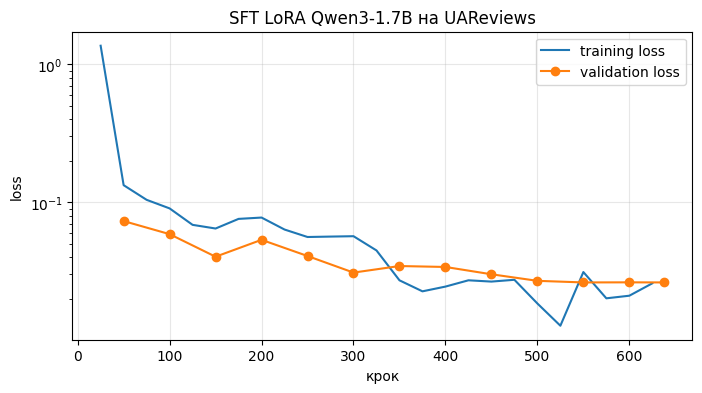

In [70]:
hist = pd.DataFrame(trainer.state.log_history)
tr = hist.dropna(subset=["loss"])[["step", "epoch", "loss"]]
ev = hist.dropna(subset=["eval_loss"])[["step", "epoch", "eval_loss"]]
loss_tbl = pd.merge_asof(ev.sort_values("step"), tr[["step", "loss"]].sort_values("step"), on="step").round(4)
display(loss_tbl.rename(columns={"loss": "train_loss (останній лог)", "eval_loss": "val_loss"}))

plt.figure(figsize=(8, 4))
plt.plot(tr.step, tr.loss, label="training loss")
plt.plot(ev.step, ev.eval_loss, "o-", label="validation loss")
plt.xlabel("крок"); plt.ylabel("loss"); plt.yscale("log"); plt.grid(alpha=.3); plt.legend()
plt.title("SFT LoRA Qwen3-1.7B на UAReviews"); plt.show()

**Тренування:** 5 104 приклади × 2 епохи = 638 кроків (батч 16), **48 хв** на T4, пікова пам'ять **6.7 ГБ** (T4 має 15 ГБ). Навчається 17.4 млн параметрів (1.0 % моделі).

Пам'ять після завантаження моделі показала 6.6 ГБ, а не ≈ 3.2 ГБ (1.72 млрд × 2 байти), як у демо 03. Найімовірніше причина в тому, що ноутбук перезапускали
в тій самій сесії Colab без *Restart runtime* (лічильник клітинок починається з 56), і в пам'яті ще лишалась попередня копія моделі. Саме тренування
LoRA на 1.7B, за демо 03, потребує ≈ 3.8 ГБ.

**Перенавчання немає:** val loss плавно спадав з 0.073 (крок 50) до 0.026 (крок 550) і далі **вийшов на плато** (0.0262-0.0263 до кінця). Train loss увесь час
був на тому самому рівні, що й val loss (0.02-0.03). Тому нічого змінювати не довелось. Найкращий чекпоінт за val loss - останній (крок 638), його й завантажено
(`load_best_model_at_end`). Друга половина другої епохи вже майже нічого не дала, тож для економії часу можна було б тренувати ≈ 1.5 епохи.

Абсолютні значення loss малі, бо loss рахується лише на 1-3 токенах мітки (`assistant_only_loss`), а модель після перших сотень кроків майже завжди впевнено
вгадує правильну мітку.

## 1.5. Порівняння до / після

Той самий тестовий набір, та сама функція `classify()`, але донавчена модель отримує **короткий** промпт.

In [71]:
tok.padding_side = "left"
t0 = time.time()
test_df["pred_after"], test_df["raw_after"] = classify(list(test_df.content), "short")
after_time = time.time() - t0
results.append(report(test_df.label, test_df.pred_after, "Qwen3-1.7B + LoRA, короткий промпт"))

n_before = np.mean([len(tok(render(t, BEST_STYLE)).input_ids) for t in test_df.content[:200]])
n_after  = np.mean([len(tok(render(t, "short")).input_ids) for t in test_df.content[:200]])
print(f"Інференс на тесті: до {before_time:.0f} с, після {after_time:.0f} с")
print(f"Токенів промпту в середньому: до {n_before:.0f}, після {n_after:.0f}")
res_df = pd.DataFrame(results).set_index("модель")
res_df

Інференс на тесті: до 407 с, після 173 с
Токенів промпту в середньому: до 824, після 167


,macro-F1,accuracy,"валідних, %",F1 подяка,F1 скарга,F1 питання,F1 пропозиція,F1 нейтральне
модель,,,,,,,,
завжди 'подяка',0.156,0.641,100.0,0.781,0.000,0.000,0.000,0.000
Qwen3-1.7B + промпт 'detailed',0.571,0.804,99.8,0.917,0.879,0.437,0.341,0.281
"Qwen3-1.7B + LoRA, короткий промпт",0.842,0.947,100.0,0.979,0.938,0.921,0.730,0.643


              precision    recall  f1-score   support

      подяка      0.979     0.979     0.979      1109
      скарга      0.935     0.941     0.938       410
     питання      0.946     0.897     0.921        97
  пропозиція      0.712     0.750     0.730        56
  нейтральне      0.649     0.638     0.643        58

    accuracy                          0.947      1730
   macro avg      0.844     0.841     0.842      1730
weighted avg      0.947     0.947     0.947      1730



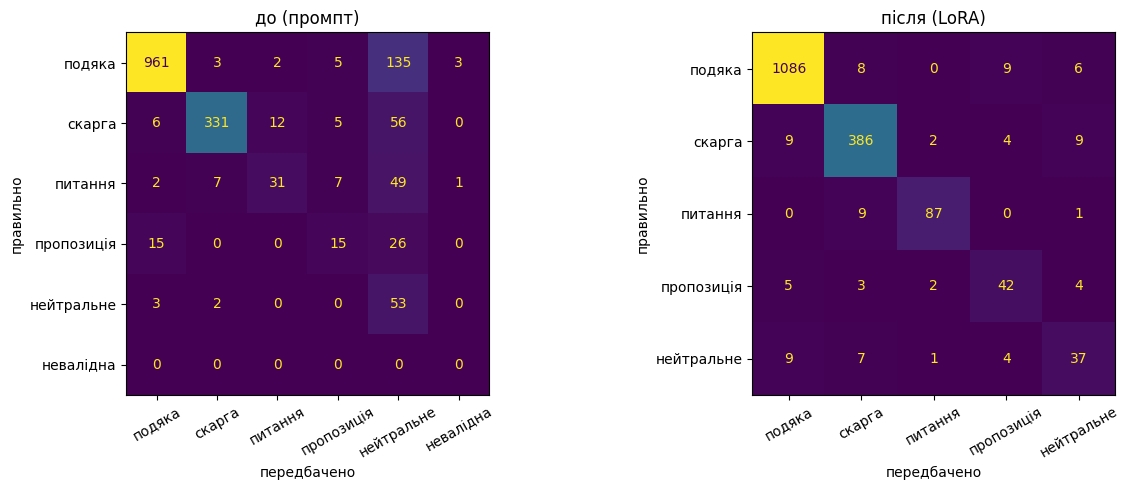

In [72]:
print(classification_report(test_df.label, test_df.pred_after, labels=CLASSES, zero_division=0, digits=3))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, col, title in [(ax[0], "pred_before", "до (промпт)"), (ax[1], "pred_after", "після (LoRA)")]:
    labels_cm = CLASSES + (["невалідна"] if (test_df[col] == "невалідна").any() else [])
    ConfusionMatrixDisplay(confusion_matrix(test_df.label, test_df[col], labels=labels_cm),
                           display_labels=labels_cm).plot(ax=a, colorbar=False, xticks_rotation=30)
    a.set_title(title); a.set_xlabel("передбачено"); a.set_ylabel("правильно")
plt.tight_layout(); plt.show()

**Порівняння до / після на тесті (1 730 відгуків):**

| | завжди "подяка" | Qwen3-1.7B + найкращий промпт | Qwen3-1.7B + LoRA |
|---|---:|---:|---:|
| **macro-F1** | 0.156 | 0.571 | **0.842** |
| accuracy | 0.641 | 0.804 | **0.947** |
| валідних відповідей | 100 % | 99.8 % | **100 %** |
| F1 подяка | 0.781 | 0.917 | **0.979** |
| F1 скарга | 0 | 0.879 | **0.938** |
| F1 питання | 0 | 0.437 | **0.921** |
| F1 пропозиція | 0 | 0.341 | **0.730** |
| F1 нейтральне | 0 | 0.281 | **0.643** |
| токенів промпту на відгук | - | 824 | **167** |
| час на весь тест | - | 407 с | **173 с** |

- **macro-F1 зросла з 0.571 до 0.842 (+0.27).** Найбільше виграли саме рідкісні класи, заради яких і робилось донавчання: F1 "питання" 0.44 → 0.92,
  "пропозиція" 0.34 → 0.73, "нейтральне" 0.28 → 0.64.
- Головну ваду промпту видно на матриці помилок "до": модель **відправляла в "нейтральне" все, де немає явної емоції** (319 таких відповідей при 58 справжніх,
  precision 0.17): питання ("мені треба подати документи…"), стримані скарги ("…але працюючих кілька, черги"), поради. Після донавчання модель вивчила,
  що анотатори вважають нейтральним лише описи без оцінки й прохання.
- На тих самих 10 прикладах: **до - 6/10, після - 10/10.**
- **Донавчена модель ще й дешевша:** промпт у 4.9 раза коротший (167 проти 824 токенів) і обробка тесту в 2.4 раза швидша (173 проти 407 с).
  На 10 000 відгуків на день це ≈ 6.6 млн токенів на день менше.

**Ті самі 10 прикладів до і після:**

In [73]:
show = test_df.loc[SHOW_IDX, ["label", "pred_before", "pred_after", "content"]].copy()
show["content"] = show.content.str[:150]
show

,label,pred_before,pred_after,content
895,нейтральне,нейтральне,нейтральне,"Старовинна , історична будівля Львова. Зараз там є пожежна частина."
1052,нейтральне,нейтральне,нейтральне,"Один із ТОП-ових вузів Харкова, головний корпус знаходиться в центрі, на площі Свободи."
479,питання,нейтральне,питання,Доброго дня мені треба подати документи нагрупу галицький район
1598,питання,нейтральне,питання,"Доброго дня! Підкажіть, будь ласка, чи має право працівник (викладач вузу) на повну відпустку 56 днів , якщо він працює на новому місті роботи більше"
784,подяка,подяка,подяка,"Щиро дякую за приємне обслуговування, привітання зі здачею успішного іспиту від керівника! Дуже приємно, що в нашій країні МВС це приємний орган, який"
1151,подяка,подяка,подяка,"Мені дуже сподобалося у Кроку тому ,що це інший світ відокремлюючий нас від реальності коли я прийшов я тільки починав програмувати та тепер я це вмію"
1635,пропозиція,нейтральне,пропозиція,Якщо не було чим платити — необхідно подавати заяву в банк. Я тут розповідаю докладно https://lexukraine.com.ua
607,пропозиція,пропозиція,пропозиція,"Щоб піднятися на оглядову вежу, варто піти до мерії. З вежі відкривається вид на Старе місто. Згаданий підйом по сходах трохи втомлює, але воно того в"
709,скарга,нейтральне,скарга,"Повинно бути зручно, окремі оператори і т.д., але працюючих кілька, черги"
1400,скарга,скарга,скарга,"Сад - гестапо, дитина, після року ходіння, навіть проходячи повз стискається від страху. Зробив велику помилку, віддавши сина у віці 2+року, коли ще н"


### Помилки донавченої моделі

In [74]:
err = test_df[test_df.label != test_df.pred_after]
print(f"Помилок: {len(err)} з {len(test_df)}")
print("Найчастіші плутанини (правильно → передбачено):")
print(err.groupby(["label", "pred_after"]).size().sort_values(ascending=False).head(8).to_string())

Помилок: 92 з 1730
Найчастіші плутанини (правильно → передбачено):
label       pred_after
нейтральне  подяка        9
скарга      нейтральне    9
питання     скарга        9
подяка      пропозиція    9
скарга      подяка        9
подяка      скарга        8
нейтральне  скарга        7
подяка      нейтральне    6


In [75]:
pd.set_option("display.max_colwidth", 300)
err_show = err.groupby(["label", "pred_after"]).head(2).sort_values(["label", "pred_after"])
err_show[["label", "pred_after", "rating", "content"]].head(16)

,label,pred_after,rating,content
1469,нейтральне,питання,2.0,За посиланнями нижче можна переглянути деякі елементи цього суду\nhttps://fb.watch/oWZf8NAQZj/\nhttps://fb.watch/pS07J69bcc/…
174,нейтральне,подяка,NaN,"Червень-2020, той самий легендарний цобакен живий-здоровий!"
247,нейтральне,подяка,4.0,"Цей університет має високий рейтинг у світі, має кілька курсів, інфраструктуру"
166,нейтральне,пропозиція,NaN,Найкраще можна побачити тільки з гори. The best views come from above
176,нейтральне,пропозиція,NaN,"Гарний вид на місто.\nАле не витрачайте час, якщо у Вас страх висоти чи сходів без поручнів. Підйом не важкий (без проблем впорався і трирічна дитина), але ось спуск ... Та й чи зможете ви розслабитися і отримати справжнє задоволення."
321,нейтральне,скарга,3.0,"Роблять ремонт у всій будівлі... а так, для юриста, всі суди однакові;)"
500,нейтральне,скарга,5.0,"Приїхали із друзями. Привезли корми котам, собакам, гризунам; повідці, нашийники. Нас поводили притулком, показали тварин. Ми погуляли із собаками, поспілкувалися з котиками. Стає сумно коли чуєш гавкіт собак, коли кожен собака чекає що його заберуть."
1720,питання,нейтральне,NaN,"? Документи, опитування, шеринг авто, оплата штрафів за порушення ПДР, скасування або отримання статусу безробітного, заміна посвідчення водія, витяг про місце проживання для дорослого та дитини, обмін лампочок, витяг про несудимість, єВідновлення — повідомлення про пошкоджене майно й подання за..."
26,питання,скарга,5.0,"Усім доброго дня. Не коли не думав, що доведеться звертатися до закладів цього напряму. Але коли завів собі собаку, то стало питання яку віт клініку вибрати. Щоб ціна та якість обслуговування збігалися і мені підказали що при КП є віт…"
134,питання,скарга,NaN,"Вас ніхто не наказував, ви і надалі можете користуватися даним чатом, я вас спеціально згадав в коментарях, щоб ви знову побачили даний чат. Вам просто треба було повторно увійти в даний чат з коментарями, а ви скоріш за все вийшли з нього, коли писали мені в особисті повідомлення, тому і витра..."


**Аналіз помилок донавченої моделі.** Помилок 92 з 1 730 (5.3 %). Плутанини розподілені рівномірно (по 6-9 на кожну пару класів),
тобто модель не має одного систематичного "перекосу". Переглянувши приклади вище, бачу кілька типів помилок:

1. **Нечітка межа "нейтральне / подяка".** Описи місць з легкою позитивною оцінкою: "Цей університет має високий рейтинг у світі, має кілька курсів, інфраструктуру"
   (еталон - нейтральне, модель - подяка). Тут і людина вагалась би: анотатори вважали опис нейтральним, модель побачила похвалу.
2. **"Раджу…" - пропозиція чи подяка?** "Я навчаюсь у цьому коледжі, раджу сюди вступати…", "Всім гостям міста раджу піднятись…" мають еталон подяка, а модель
   каже пропозиція. Розмітка тут непослідовна: у тренувальному прикладі, який ноутбук показав у 1.4 ("Тут можна піднятися на вежу… чудовий краєвид"), стоїть саме **пропозиція**.
   Модель вивчила одну з двох суперечливих конвенцій. Це шум у даних, а не помилка моделі.
3. **Іронія і змішані почуття.** "Електронна черга і туалет - що ще треба від державних установ? :)" і "Сьогодні черги немає приємно" мають еталон подяка, а модель
   каже скарга: слово "черга" в більшості тренувальних прикладів означає скаргу, а іронію чи заперечення ("черги **немає**") мала модель зчитує гірше.
   "Чисто, затишно, трохи совкове обслуговування" - похвала і критика в одному реченні.
4. **Питання всередині скарги** (питання → скарга, 9 випадків): довгі відгуки, де людина спочатку описує проблему, а потім питає, куди звернутися.
   Головний намір неоднозначний.
5. **Помилки розмітки.** "Вас ніхто не наказував, ви і надалі можете користуватися даним чатом…" має еталон **питання**, хоча це відповідь модератора, а не питання громадянина;
   набір посилань без тексту має еталон "нейтральне", модель сказала "питання".

Найгірше модель розрізняє **нейтральне (F1 0.64)** і **пропозиції (F1 0.73)**: це найменші класи (260 і 231 тренувальний приклад) з найсуб'єктивнішими межами.
Великі класи з чіткими сигналами (подяка, скарга, питання) мають F1 0.92-0.98.

### Чи не зіпсувалась модель на загальних запитах

LoRA-адаптер можна вимкнути (`model.disable_adapter()`), тому порівнюю відповіді **тієї самої** моделі без адаптера й з ним
на запитах, що не стосуються класифікації.

In [76]:
GENERAL = [
    "Поясни простими словами, що таке інфляція. Дві-три речення.",
    "Напиши функцію на Python, яка перевіряє, чи є рядок паліндромом.",
    "Яка столиця Канади?",
    "Скільки буде 17 * 23?",
    "Порадь, як підготуватися до співбесіди на посаду дата-аналітика. Три пункти.",
]

@torch.no_grad()
def chat(q, max_new_tokens=160):
    p = tok.apply_chat_template([{"role": "user", "content": q}], tokenize=False,
                                add_generation_prompt=True, enable_thinking=False)
    enc = tok(p, return_tensors="pt").to(model.device)
    out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, temperature=None, top_p=None, top_k=None)
    return tok.decode(out[0, enc.input_ids.shape[1]:], skip_special_tokens=True).strip()

for q in GENERAL:
    with model.disable_adapter():
        a0 = chat(q)
    a1 = chat(q)
    print(f"### {q}\n--- без адаптера:\n{a0}\n--- з адаптером:\n{a1}\n")

### Поясни простими словами, що таке інфляція. Дві-три речення.
--- без адаптера:
Інфляція — це природа, коли ціни на товари і послуги зростають, але вартість грошей зменшуються. Це означає, що кожен день ви платите більше за те, що отримуєте. Наприклад, якщо під час року ціна хліба збільшилася, то ви маєте більше грошей, щоб купити той самий хліб.
--- з адаптером:
Інфляція — це приріст цін на товари і послуги у країні, який відбувається через збільшення попиту на них або зменшення виробництва. Це може призвести до того, що люди мають менші кошти, але виробництво зменшується.

### Напиши функцію на Python, яка перевіряє, чи є рядок паліндромом.
--- без адаптера:
Ось функція на Python, яка перевіряє, чи є заданий рядок паліндромом:

```python
def is_palindrome(s):
    # Видалити пробіли та символи відступу та перетворити рядок в нижній регістр
    cleaned = s.replace(" ", "").lower()
    
    # Перевіряємо, чи рядок є паліндромом
    return cleaned == cleaned[::-1]
```

### Приклад вико

Тест у "чужому" форматі: відгук, але просимо **пояснити** класифікацію. Якщо модель перенавчилась на формат, вона відповідатиме лише одним словом.

In [77]:
q = ("Ось відгук: 'Чекала в ЦНАПі 3 години, а потім сказали прийти завтра'. "
     "Поясни в одному реченні, чому це скарга, і запропонуй, що ЦНАП міг би покращити.")
with model.disable_adapter():
    print("без адаптера:", chat(q, 120))
print("\nз адаптером: ", chat(q, 120))

без адаптера: Це скарга, оскільки відгукувався на те, що відсутність часу (3 години) призвела до того, що він не мог прийти до ЦНАП у вказаному часі. ЦНАП міг би покращити процес збору заяв, встановивши більш конкретні і термінові умови для приходу, а також відпові

з адаптером:  Це скарга, оскільки відсутність відповіді від ЦНАП у вказані 3 години викликає несприятливу відчути, що відбулося. ЦНАП може покращити, відповіді відправляти відповідно до дати, а також збільшити час на відповідь


**Висновок щодо загальних запитів.** Модель загалом **не зламалась**:
- код для паліндрома правильний, 17 × 23 = 391 правильно, поради до співбесіди мають ту саму структуру; про інфляцію відповідь з адаптером навіть точніша, ніж без нього
  (без адаптера модель написала, що через інфляцію "ви маєте більше грошей");
- на запит у "чужому" форматі (пояснити, чому це скарга) модель з адаптером відповіла **реченням із поясненням і порадою**, а не одним словом
  "скарга". Тобто формат відповіді одним словом закріпився лише для нашого системного промпту, а не для всіх запитів;
- відповіді з адаптером стали **коротшими** (17 × 23 одним рядком замість розписаного розв'язку): модель вчилась відповідати коротко;
- **є одна помітна регресія:** на "Яка столиця Канади?" модель з адаптером відповіла **"Ванкувер"**, а без адаптера правильно - Оттава.
  Це ознака "дрейфу" загальних знань після донавчання: LoRA змінює ваги всіх лінійних шарів, і на межових фактах найімовірніший токен може змінитись.

На практиці це не проблема для нашого сценарію: адаптер вмикається лише для класифікації відгуків, а для інших запитів його можна вимкнути
(`disable_adapter()`) або обслуговувати базову модель окремо. Якби модель мала одночасно класифікувати й вести загальний діалог, варто було б
додати в тренування частину загальних діалогів або зменшити `r` / кількість кроків.

### Збереження результатів і (за бажанням) публікація адаптера

Ваги адаптера в репозиторій не додаю. Для публікації на Hugging Face Hub додайте токен з правом запису
в Colab Secrets під іменем `HF_TOKEN` і поставте `PUSH_TO_HUB = True`.

In [78]:
summary = {
    "results": results, "best_prompt": BEST_STYLE, "train_examples": len(train_df), "val_examples": len(val_df),
    "test_examples": len(test_df), "train_minutes": round(train_time / 60, 1), "peak_gpu_gb": round(peak_mem, 2),
    "steps": trainer.state.global_step, "best_eval_loss": round(trainer.state.best_metric, 4),
    "prompt_tokens_before": round(n_before), "prompt_tokens_after": round(n_after),
    "infer_sec_before": round(before_time), "infer_sec_after": round(after_time),
}
json.dump(summary, open("ft_results.json", "w"), ensure_ascii=False, indent=1)
print(json.dumps(summary, ensure_ascii=False, indent=1))

PUSH_TO_HUB = False
HUB_REPO = "qwen3-1.7b-uareviews-intent-lora"
if PUSH_TO_HUB:
    from google.colab import userdata
    from huggingface_hub import login
    login(userdata.get("HF_TOKEN"))
    model.push_to_hub(HUB_REPO, private=False)
    tok.push_to_hub(HUB_REPO, private=False)

{
 "results": [
  {
   "модель": "завжди 'подяка'",
   "macro-F1": 0.156,
   "accuracy": 0.641,
   "валідних, %": 100.0,
   "F1 подяка": 0.781,
   "F1 скарга": 0.0,
   "F1 питання": 0.0,
   "F1 пропозиція": 0.0,
   "F1 нейтральне": 0.0
  },
  {
   "модель": "Qwen3-1.7B + промпт 'detailed'",
   "macro-F1": 0.571,
   "accuracy": 0.804,
   "валідних, %": 99.8,
   "F1 подяка": 0.917,
   "F1 скарга": 0.879,
   "F1 питання": 0.437,
   "F1 пропозиція": 0.341,
   "F1 нейтральне": 0.281
  },
  {
   "модель": "Qwen3-1.7B + LoRA, короткий промпт",
   "macro-F1": 0.842,
   "accuracy": 0.947,
   "валідних, %": 100.0,
   "F1 подяка": 0.979,
   "F1 скарга": 0.938,
   "F1 питання": 0.921,
   "F1 пропозиція": 0.73,
   "F1 нейтральне": 0.643
  }
 ],
 "best_prompt": "detailed",
 "train_examples": 5104,
 "val_examples": 810,
 "test_examples": 1730,
 "train_minutes": 48.0,
 "peak_gpu_gb": 6.69,
 "steps": 638,
 "best_eval_loss": 0.0262,
 "prompt_tokens_before": 824,
 "prompt_tokens_after": 167,
 "infer_sec_

## 1.6. Мій звіт

- **Задача і чому потрібне донавчання:** класифікувати відгуки громадян про держпослуги (Дія, ЦНАП, міськради) за наміром: подяка, скарга, питання / прохання
  про допомогу, пропозиція, нейтральне. За міткою відгук потрапляє в потрібну чергу: питання - в підтримку, скарги - на розбір, пропозиції - продуктовій команді.
  Користувач - оператор чи аналітик, вхід - текст відгуку, вихід - одна мітка. Промпту недостатньо, бо межі класів - це конвенції конкретної розмітки
  (що вважати нейтральним, де закінчується скарга й починається питання), і саме на рідкісних класах мала модель з промптом помиляється; до того ж
  детальний промпт з описами й прикладами (≈ 770 токенів) у рази довший за сам відгук. RAG не допоможе, бо бракує не знань, а навички класифікувати за заданою схемою.

- **Модель і дані:** `Qwen/Qwen3-1.7B` (instruct, режим міркувань вимкнено). Instruct, щоб можна було чесно порівняти з промптом; 1.7B - компроміс: помітно сильніша
  за 0.6B (демо 03) і в fp16 тренується з LoRA на T4. Дані - [UAReviews](https://huggingface.co/datasets/KSE-RESEARCH-Group/UAReviews)
  (KSE, CC-BY-4.0): 11 565 українських відгуків у JSONL, поля `content` → `final_category`. Поділ: тест - офіційний спліт `test` (1 730),
  валідація - 10 % від `train` (810), тренування - решта `train` з обмеженням подяк до 2 500 (5 104 приклади). Перевірено, що тексти тесту не потрапили в тренування.

- **Метрика й результат до донавчання:** macro-F1, бо класи дуже нерівні (64 % подяк), а найважливіші - рідкісні (питання 5.6 %, пропозиції 3.2 %).
  Базовий рівень "завжди подяка": macro-F1 **0.156** (accuracy 0.641). Qwen3-1.7B з найкращим промптом (обраним на валідації: визначення класів, правила,
  5 прикладів, 824 токени): macro-F1 **0.571**, accuracy 0.804. Головна вада - надмірне "нейтральне" (319 відповідей при 58 справжніх) і низький recall питань (32 %) та пропозицій (27 %).

- **Метод донавчання й гіперпараметри:** SFT з LoRA (TRL + PEFT): `r=16`, `lora_alpha=32`, `lora_dropout=0.05`, `target_modules="all-linear"`
  (17.4 млн параметрів, 1 % моделі); learning rate 2e-4, cosine, warmup 30 кроків; батч 8 × grad accum 2 = 16; 2 епохи (638 кроків); `max_length=384`; fp16;
  gradient checkpointing; `assistant_only_loss=True` і `enable_thinking=False`, як у демо 03. Повне донавчання не влазить у T4 (≈ 27 ГБ), QLoRA не потрібна,
  бо модель у fp16 займає лише 3.4 ГБ. Тренування тривало **48 хв**, пікова пам'ять GPU **6.7 ГБ**. Val loss спадав з 0.073 до 0.026 і вийшов на плато,
  перенавчання немає.

- **Результат після донавчання:** macro-F1 **0.842** (+0.27), accuracy **0.947**, 100 % валідних відповідей. F1 по класах: подяка 0.98, скарга 0.94, питання **0.92** (було 0.44),
  пропозиція **0.73** (було 0.34), нейтральне **0.64** (було 0.28). На 10 фіксованих прикладах - 10/10 проти 6/10. Промпт у 4.9 раза коротший (167 проти 824 токенів),
  обробка тесту в 2.4 раза швидша. На загальних запитах модель відповідає нормально (код, арифметика, поради, пояснення не одним словом),
  але з'явилась одна фактична помилка ("столиця Канади - Ванкувер"), тож адаптер варто вмикати лише для класифікації.

- **Аналіз помилок:** 92 помилки з 1 730 (5.3 %), без одного домінуючого типу. Причини: суб'єктивна межа "нейтральне / подяка" в описах місць;
  непослідовна розмітка порад ("раджу…" буває і подякою, і пропозицією); іронія і змішані почуття ("Електронна черга і туалет - що ще треба? :)",
  "черги немає - приємно" → скарга через слово "черга"); питання всередині скарг; явні помилки в еталоні (відповідь модератора розмічена як питання).
  Найслабші класи - нейтральне й пропозиції: найменше прикладів і найрозмитіші межі.

- **Висновок:** донавчання малої моделі на 5 тис. прикладів дало те, чого не вдалося досягти промптом: macro-F1 0.57 → 0.84, а F1 рідкісних класів зросла
  вдвічі. До того ж донавчена модель у 5 разів економніша за токенами і її можна запускати локально, не передаючи персональні дані громадян у зовнішній API.
  Обмеження: слабші нейтральне й пропозиції, шум у розмітці, невелика втрата загальних знань. Що зробив би далі: почистив би суперечливі мітки "раджу…",
  перевірив модель на складнішому спліті `challenge`, спробував Qwen3-4B через QLoRA, опублікував адаптер на Hugging Face Hub.